<a href="https://colab.research.google.com/github/sanchit-Thakur/ML-COURSE/blob/main/FCC_Bikes_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
import copy
import tensorflow as tf
import seaborn as sns
from sklearn.linear_model import LinearRegression

dataset :- https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand

In [ ]:
dataset_cols = 	["Rented Bike Count",	"Hour",	"Temperature", 	"Humidity(%)",	"Wind speed (m/s)",	"Visibility (10m)",	"Dew point temperature(�C)",	"Solar Radiation (MJ/m2)"	,"Rainfall(mm)"	,"Snowfall (cm)",	"Seasons"	,"Holiday",	"Functioning Day"]
df = pd.read_csv("/content/SeoulBikeData.csv", encoding="unicode_escape").drop(["Date" , "Holiday" , "Seasons"] , axis = 1)

In [ ]:
df.cols = dataset_cols
df["Functioning Day"] = (df["Functioning Day"] == "Yes").astype(int)
df = df[df["Hour" ] == 12]
df = df.drop(["Hour"], axis = 1)

/tmp/ipykernel_1538/2199631160.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.cols = dataset_cols


In [ ]:
df.head()

,Rented Bike Count,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Functioning Day
12,449,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,1
36,479,4.3,41,1.3,1666,-7.8,1.09,0.0,0.0,1
60,333,5.8,85,1.7,349,3.4,0.43,0.0,0.0,1
84,393,-0.3,38,4.8,1823,-12.9,1.11,0.0,0.0,1
108,321,-2.3,25,0.0,1962,-19.7,0.00,0.0,0.0,1


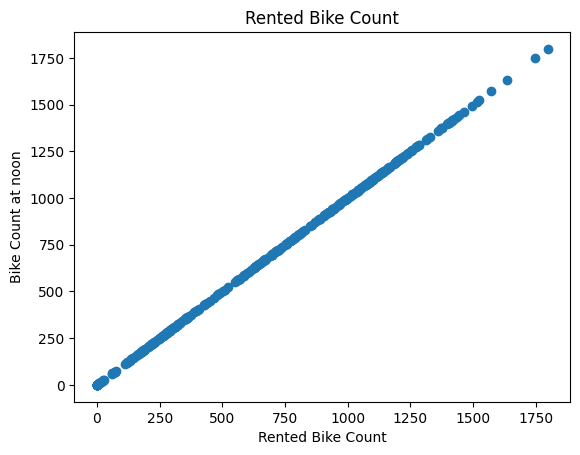

In [ ]:
for label in df.columns[:1]:
  plt.scatter(df[label], df["Rented Bike Count"])
  plt.title(label)
  plt.ylabel("Bike Count at noon")
  plt.xlabel(label)
  plt.show()

In [ ]:
df = df.drop(["Wind speed (m/s)", "Visibility (10m)", "Functioning Day"], axis=1, errors='ignore')
df.head()

,Rented Bike Count,Temperature(°C),Humidity(%),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
12,449,1.7,23,-17.2,1.11,0.0,0.0
36,479,4.3,41,-7.8,1.09,0.0,0.0
60,333,5.8,85,3.4,0.43,0.0,0.0
84,393,-0.3,38,-12.9,1.11,0.0,0.0
108,321,-2.3,25,-19.7,0.00,0.0,0.0


TRAIN / VALID / TEST DATASET

In [ ]:
train, val, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
def get_xy(dataframe, y_label, x_labels=None):
  dataframe = copy.deepcopy(dataframe)
  y = dataframe[y_label].values
  if x_labels is None:
    X = dataframe[[c for c in dataframe.columns if c != y_label]].values
  else:
    if len(x_labels) == 1:
      X = dataframe[x_labels[0]].values.reshape(-1, 1)
    else:
      X = dataframe[x_labels].values
  return dataframe, X, y

In [ ]:
_ , x_train_temp , y_train_temp = get_xy(train, "Rented Bike Count")
_ , x_val_temp , y_val_temp = get_xy(val, "Rented Bike Count")
_ , x_test_temp , y_test_temp = get_xy(test, "Rented Bike Count")

In [ ]:
x_train_temp

array([[26.2 , 31.  ,  7.7 ,  3.18,  0.  ,  0.  ],
       [ 4.  , 37.  , -9.4 ,  1.75,  0.  ,  0.  ],
       [10.8 , 49.  ,  0.4 ,  1.45,  0.  ,  0.  ],
       ...,
       [ 8.1 , 51.  , -1.4 ,  0.75,  0.  ,  0.  ],
       [11.9 , 74.  ,  7.4 ,  1.84,  0.  ,  0.  ],
       [23.1 , 64.  , 15.9 ,  1.35,  0.  ,  0.  ]], shape=(219, 6))

In [ ]:
x_val_temp

array([[ 5.50e+00,  2.50e+01, -1.30e+01,  2.28e+00,  0.00e+00,  0.00e+00],
       [ 1.00e+01,  3.90e+01, -3.30e+00,  2.20e+00,  0.00e+00,  0.00e+00],
       [ 1.98e+01,  4.90e+01,  8.70e+00,  3.17e+00,  0.00e+00,  0.00e+00],
       [ 3.66e+01,  4.10e+01,  2.12e+01,  2.58e+00,  0.00e+00,  0.00e+00],
       [ 2.03e+01,  3.40e+01,  3.90e+00,  2.85e+00,  0.00e+00,  0.00e+00],
       [ 2.64e+01,  4.60e+01,  1.38e+01,  3.26e+00,  0.00e+00,  0.00e+00],
       [ 5.30e+00,  5.50e+01, -3.00e+00,  8.50e-01,  0.00e+00,  0.00e+00],
       [ 1.57e+01,  4.60e+01,  4.00e+00,  3.05e+00,  0.00e+00,  0.00e+00],
       [ 3.68e+01,  4.10e+01,  2.13e+01,  2.53e+00,  0.00e+00,  0.00e+00],
       [ 2.78e+01,  4.70e+01,  1.54e+01,  2.99e+00,  0.00e+00,  0.00e+00],
       [-3.00e-01,  4.50e+01, -1.08e+01,  1.01e+00,  0.00e+00,  0.00e+00],
       [-4.90e+00,  2.50e+01, -2.19e+01,  1.08e+00,  0.00e+00,  0.00e+00],
       [ 2.05e+01,  3.70e+01,  5.20e+00,  2.94e+00,  0.00e+00,  0.00e+00],
       [-4.60e+00,  3.20e

In [ ]:
x_test_temp

array([[ 24.2 ,  50.  ,  13.1 ,   2.85,   0.  ,   0.  ],
       [ 14.9 ,  40.  ,   1.4 ,   2.06,   0.  ,   0.  ],
       [ 10.3 ,  38.  ,  -3.4 ,   1.08,   0.  ,   0.  ],
       [ 14.6 ,  53.  ,   5.1 ,   2.65,   0.  ,   0.  ],
       [  4.5 ,  56.  ,  -3.5 ,   0.71,   0.  ,   0.  ],
       [ -7.8 ,  28.  , -23.1 ,   2.12,   0.  ,   0.  ],
       [ 33.2 ,  59.  ,  24.  ,   2.37,   0.  ,   0.  ],
       [ -1.  ,  35.  , -14.5 ,   0.64,   0.  ,   3.  ],
       [ -2.5 ,  31.  , -17.3 ,   1.08,   0.  ,   2.3 ],
       [ -4.1 ,  28.  , -19.9 ,   1.08,   0.  ,   0.  ],
       [ 32.  ,  57.  ,  22.4 ,   1.94,   0.  ,   0.  ],
       [ 22.2 ,  50.  ,  11.2 ,   2.65,   0.  ,   0.  ],
       [  5.6 ,  27.  , -11.9 ,   0.34,   0.  ,   0.  ],
       [ 25.8 ,  81.  ,  22.2 ,   0.8 ,   0.  ,   0.  ],
       [ 10.6 ,  52.  ,   1.1 ,   2.27,   0.  ,   0.  ],
       [-11.3 ,  27.  , -26.6 ,   1.18,   0.  ,   1.  ],
       [ 10.4 ,  41.  ,  -2.3 ,   1.33,   0.  ,   0.  ],
       [  7.9 ,  14.  , -18.  ,

In [ ]:
temp_reg = LinearRegression()
temp_reg.fit(x_train_temp, y_train_temp)

LinearRegression()

In [ ]:
temp_reg.score(x_train_temp, y_train_temp)

0.47845459682756897

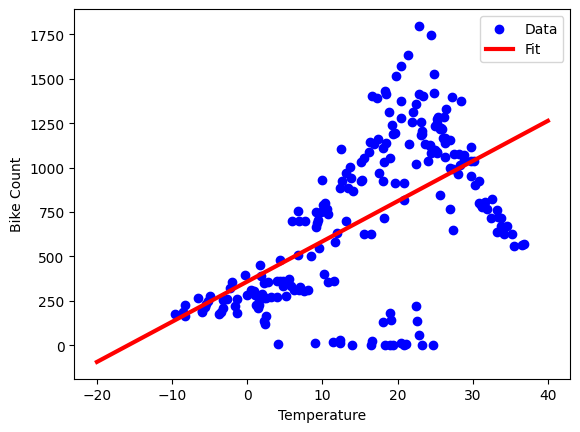

In [ ]:
# 1. Extract only the Temperature column (index 0)
x_train_temp_single = x_train_temp[:, 0].reshape(-1, 1)

# 2. Re-fit the linear regression using only Temperature
temp_reg_single = LinearRegression()
temp_reg_single.fit(x_train_temp_single, y_train_temp)

# 3. Plot the scatter points and the fit line
plt.scatter(x_train_temp_single, y_train_temp, label="Data", color="blue")
x_line = tf.linspace(-20, 40, 100)
plt.plot(x_line, temp_reg_single.predict(np.array(x_line).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.xlabel("Temperature")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

Multiple Linear Regresion

In [ ]:
train, val, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])
_ , x_train_all , y_train_all = get_xy(train, "Rented Bike Count", x_labels=df.columns[1:])
_ , x_val_all , y_val_all = get_xy(val, "Rented Bike Count", x_labels=df.columns[1:])
_ , x_test_all , y_test_all = get_xy(test, "Rented Bike Count", x_labels=df.columns[1:])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
all_reg = LinearRegression()
all_reg.fit(x_train_all, y_train_all)

LinearRegression()

In [ ]:
all_reg.score(x_train_all, y_train_all)

0.43740000188909345

In [ ]:
all_reg.predict(x_test_all)

array([ 306.53566238, 1054.70924312,  367.82765235,  430.58646601,
        986.54788567,  663.64752962,  656.32551303,  226.38692486,
         99.67216778,  452.22855588,  998.61092013,  504.8565578 ,
        266.95085271, 1004.61492741,  992.15490032,  802.93902694,
        464.45153735,  567.05296867,  989.84711985,  312.93906455,
        829.69568497,  687.71504023,  473.61386277, 1139.27169474,
        834.46935708,  223.12997427,  776.16939774,  458.68828423,
        732.0606168 ,  771.43466614,  785.86674385, 1053.09388617,
        393.43505399, 1077.79359611,  936.21749603,  779.13732246,
        314.02297439, 1115.00602364,  692.71590497,  632.9920421 ,
        947.02705082,  365.66314424, 1027.97726726,  908.60138778,
        517.69059799,  479.55631022,  907.12093548,  621.62240773,
        940.52009301,  872.3418271 ,  826.81081365,  257.22562641,
       1022.89708945,  485.46788136,  933.43517059,  556.6712482 ,
         78.51851636,  965.61983395,  385.51929295,  571.56277

Regression with Neural Net

In [ ]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=[1,], axis=None)
temp_normalizer.adapt(x_train_temp.reshape(-1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
train_nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(1)
])

In [ ]:
train_nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.1), loss = "mean_squared_error")


In [ ]:
# Rebuild and compile the model fresh to clear the corrupted tf.function graph state
train_nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(1)
])

train_nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss="mean_squared_error"
)

history = train_nn_model.fit(
    x_train_temp[:, 0].reshape(-1, 1),
    y_train_temp,
    epochs=100,
    verbose=0,
    validation_data=(x_val_temp[:, 0].reshape(-1, 1), y_val_temp)
)

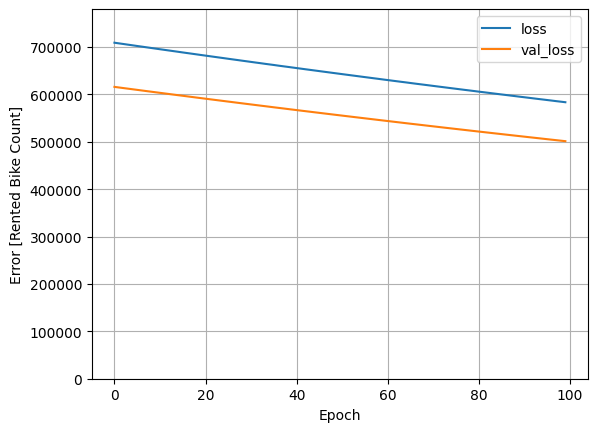

In [ ]:
def plot_loss(history):
    plt.plot(history.history['loss'], label='loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.ylim([0, max(max(history.history['loss']), max(history.history['val_loss'])) * 1.1])
    plt.xlabel('Epoch')
    plt.ylabel('Error [Rented Bike Count]')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


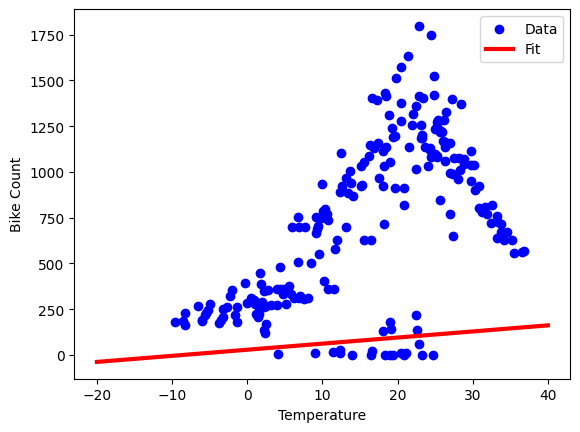

In [ ]:
# 1. Extract only the Temperature column (index 0)
x_train_temp_single = x_train_temp[:, 0].reshape(-1, 1)

# 2. Re-fit the linear regression using only Temperature
temp_reg_single = LinearRegression()
temp_reg_single.fit(x_train_temp_single, y_train_temp)

# 3. Plot the scatter points and the fit line
plt.scatter(x_train_temp_single, y_train_temp, label="Data", color="blue")
x_line = tf.linspace(-20, 40, 100)
plt.plot(x_line, train_nn_model.predict(np.array(x_line).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.xlabel("Temperature")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

Neural Net


In [ ]:
nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='relu')
])
nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss = "mean_squared_error")

In [ ]:
# 1. Create and adapt a normalizer for all 6 features
all_normalizer = tf.keras.layers.Normalization(axis=-1)
all_normalizer.adapt(x_train_all)

# 2. Re-build the neural network model using the new normalizer
nn_model = tf.keras.Sequential([
    all_normalizer,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='relu')
])

# 3. Re-compile the model
nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

# 4. Train the model on the full 6 features
history = nn_model.fit(
    x_train_all,
    y_train_all,
    epochs=100,
    verbose=0,
    validation_data=(x_val_all, y_val_all)
)

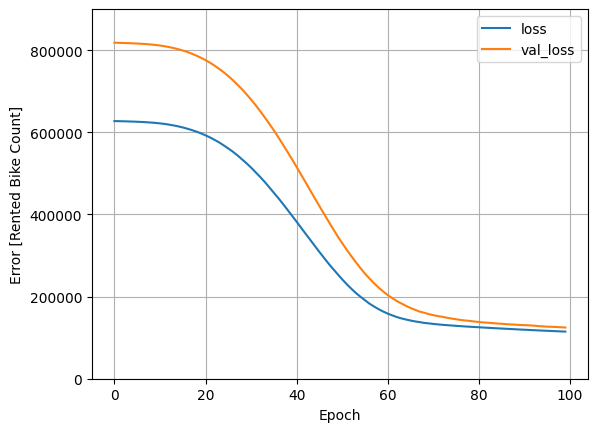

In [ ]:
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


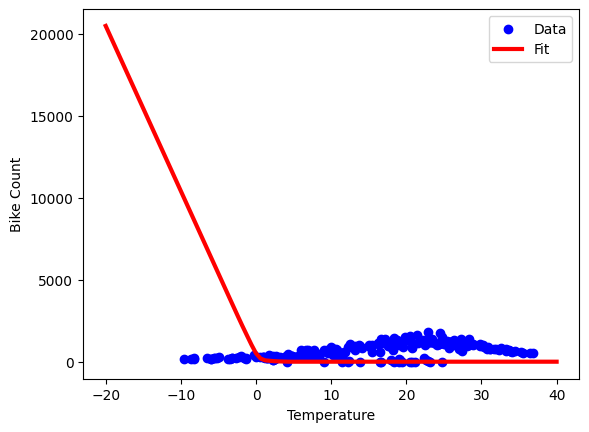

In [ ]:
# 1. Extract only the Temperature column (index 0)
x_train_temp_single = x_train_temp[:, 0].reshape(-1, 1)

# 2. Re-fit the linear regression using only Temperature
temp_reg_single = LinearRegression()
temp_reg_single.fit(x_train_temp_single, y_train_temp)

# 3. Plot the scatter points and the fit line
plt.scatter(x_train_temp_single, y_train_temp, label="Data", color="blue")
x_line = tf.linspace(-20, 40, 100)
plt.plot(x_line, nn_model.predict(np.array(x_line).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.xlabel("Temperature")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

In [ ]:
# 1. Recreate and adapt the normalizer with correct 2D tabular dimensions
all_normalizer = tf.keras.layers.Normalization(axis=-1)
all_normalizer.adapt(x_train_all)

# 2. Rebuild the sequential model using the correct normalizer
nn_model = tf.keras.Sequential([
    all_normalizer,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='relu')
])

# 3. Re-compile the model
nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

# 4. Train the model on the full 6 features
history = nn_model.fit(
    x_train_all,
    y_train_all,
    epochs=100,
    verbose=0,
    validation_data=(x_val_all, y_val_all)
)

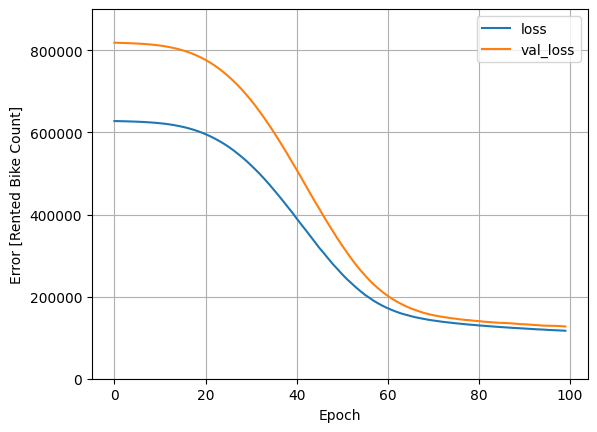

In [ ]:
plot_loss(history)

In [ ]:
all_reg.predict(x_test_all)

array([ 306.53566238, 1054.70924312,  367.82765235,  430.58646601,
        986.54788567,  663.64752962,  656.32551303,  226.38692486,
         99.67216778,  452.22855588,  998.61092013,  504.8565578 ,
        266.95085271, 1004.61492741,  992.15490032,  802.93902694,
        464.45153735,  567.05296867,  989.84711985,  312.93906455,
        829.69568497,  687.71504023,  473.61386277, 1139.27169474,
        834.46935708,  223.12997427,  776.16939774,  458.68828423,
        732.0606168 ,  771.43466614,  785.86674385, 1053.09388617,
        393.43505399, 1077.79359611,  936.21749603,  779.13732246,
        314.02297439, 1115.00602364,  692.71590497,  632.9920421 ,
        947.02705082,  365.66314424, 1027.97726726,  908.60138778,
        517.69059799,  479.55631022,  907.12093548,  621.62240773,
        940.52009301,  872.3418271 ,  826.81081365,  257.22562641,
       1022.89708945,  485.46788136,  933.43517059,  556.6712482 ,
         78.51851636,  965.61983395,  385.51929295,  571.56277

calculate the MSE for both reg and NN

In [ ]:

# 1. Ensure df and get_xy exist
try:
  df
  get_xy
except NameError:
  print("Restoring df and get_xy from /content/SeoulBikeData.csv...")
  dataset_cols = [
      "Rented Bike Count",
      "Hour",
      "Temperature",
      "Humidity(%)",
      "Wind speed (m/s)",
      "Visibility (10m)",
      "Dew point temperature(°C)",
      "Solar Radiation (MJ/m2)",
      "Rainfall(mm)",
      "Snowfall (cm)",
      "Seasons",
      "Holiday",
      "Functioning Day",
  ]
  df = pd.read_csv(
      "/content/SeoulBikeData.csv", encoding="unicode_escape"
  ).drop(["Date", "Holiday", "Seasons"], axis=1)
  df.columns = dataset_cols
  df["Functioning Day"] = (df["Functioning Day"] == "Yes").astype(int)
  df = df[df["Hour"] == 12].drop(["Hour"], axis=1)
  df = df.drop(
      ["Wind speed (m/s)", "Visibility (10m)", "Functioning Day"],
      axis=1,
      errors="ignore",
  )

  def get_xy(dataframe, y_label, x_labels=None):
    dataframe = copy.deepcopy(dataframe)
    y = dataframe[y_label].values
    if x_labels is None:
      X = dataframe[[c for c in dataframe.columns if c != y_label]].values
    elif len(x_labels) == 1:
      X = dataframe[x_labels[0]].values.reshape(-1, 1)
    else:
      X = dataframe[x_labels].values
    return dataframe, X, y


# 2. Ensure train/val/test splits exist
try:
  x_train_all
  x_val_all
  x_test_all
  y_train_all
  y_val_all
  y_test_all
except NameError:
  print("Splitting datasets because splits were not found in active namespace...")
  train, val, test = np.split(
      df.sample(frac=1, random_state=42),
      [int(0.6 * len(df)), int(0.8 * len(df))],
  )
  _, x_train_all, y_train_all = get_xy(
      train, "Rented Bike Count", x_labels=df.columns[1:]
  )
  _, x_val_all, y_val_all = get_xy(
      val, "Rented Bike Count", x_labels=df.columns[1:]
  )
  _, x_test_all, y_test_all = get_xy(
      test, "Rented Bike Count", x_labels=df.columns[1:]
  )

# 3. Ensure LinearRegression model exists
try:
  all_reg
except NameError:
  print("Re-training LinearRegression model...")
  all_reg = LinearRegression()
  all_reg.fit(x_train_all, y_train_all)

# 4. Ensure Neural Network model exists
try:
  nn_model
except NameError:
  print("Re-building and training nn_model...")
  all_normalizer = tf.keras.layers.Normalization(axis=-1)
  all_normalizer.adapt(x_train_all)

  nn_model = tf.keras.Sequential([
      tf.keras.Input(shape=(x_train_all.shape[1],)),
      all_normalizer,
      tf.keras.layers.Dense(32, activation="relu"),
      tf.keras.layers.Dense(32, activation="relu"),
      tf.keras.layers.Dense(1, activation="relu"),
  ])
  nn_model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
      loss="mean_squared_error",
  )
  nn_model.fit(
      x_train_all,
      y_train_all,
      epochs=100,
      verbose=0,
      validation_data=(x_val_all, y_val_all),
  )

# 5. Generate predictions
y_pred_lr = all_reg.predict(x_test_all)
y_pred_nn = nn_model.predict(x_test_all, verbose=0).flatten()

In [ ]:
def MSE(y_pred, y_real):
  (np.square(y_pred - y_real)).mean()

In [ ]:
MSE(y_pred_nn, y_test_all)

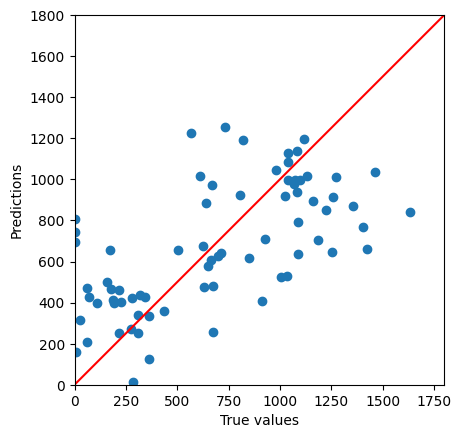

In [ ]:
ax = plt.axes(aspect='equal')
plt.scatter(y_test_all, y_pred_nn)
plt.xlabel('True values')
plt.ylabel('Predictions')
lims = [0, 1800]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, c="red")